In [ ]:
import json
from pathlib import Path

import numpy as np

from course_package import MARLEnv
from course_package.utils.helpers import (
    evaluate_expert,
    evaluate_marl_policy,
    export_submission,
    make_expert,
    make_shared_policy,
)
from course_package.utils.plots import plot_learning_curves, plot_reward_distribution

ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "training"
print("Working directory:", ROOT)

Working directory: /home/linux_user/GitRepos/ML4CE-RL


# **Coursework 2: Reinforcement Learning**
🎯 **Objectives:**
- Solve a dynamic optimization problem as Reinforcement Learning (RL)
- Interact with a multi-agent RL environment
- Experiment with different policy training algorithms 

✏️ **Your task:** become an expert RL engineer and develop a policy-based algorithm capable of solving the proposed energy management problem.

## **1. Environment definition**
<p align="center">
  <img
    src=data/schema.png
    alt="Energy microgrid schema"
    width="500"
  />
</p>

### **Basic usage**
Create an environment instance.

In [2]:
with open(DATA_DIR / "env_config.json", "r", encoding="utf-8") as f:
    env_config = json.load(f)

env = MARLEnv(env_config)
num_agents = env.num_agents
print(f"Created MARLEnv with {num_agents} agents.")

Created MARLEnv with 5 agents.


Reset the environment (initiate a new episode).

In [3]:
obs, info = env.reset(seed=42)

Inspect the **observation space**. Observations correspond to time stamps, parameter forecasts or measurements.

In [4]:
num_features = env.observation_space.shape[1]
print("Observation space:", type(env.observation_space))
print("    - Shape:", env.observation_space.shape, "[num_agents, num_features]")
print("    - Number of features/observations:", num_features)
print("    - Feature names:", env.active_observations)

Observation space: <class 'gymnasium.spaces.box.Box'>
    - Shape: (5, 35) [num_agents, num_features]
    - Number of features/observations: 35
    - Feature names: ['hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'external_temp', 'external_temp_pred1', 'external_temp_pred2', 'indoor_temp', 'indoor_temp_setpoint', 'setpoint_difference', 'hvac_mode', 'grid_cost_coeff', 'grid_cost_coeff_pred1', 'grid_cost_coeff_pred2', 'ev_soc', 'pv_generation', 'domestic_load', 'domestic_load_pred1', 'domestic_load_pred2', 'ev_availability', 'ev_trip_demand', 'ev_time_to_departure', 'ev_required_soc_departure', 'rated_power', 'cop', 'installed_capacity', 'battery_capacity', 'battery_soc_min', 'b_in_max', 'b_out_max', 'ch_efficiency', 'disch_efficiency', 'consumption']


<div class="alert alert-block alert-warning">
<b>⚠️Attention:</b> observations are already normalized to $[-1, 1]$.
</div>

Besides time-varying signals, every agent also observes static features of its own prosumer: heat pump (`rated_power`, `cop`), PV (`installed_capacity`) and EV battery (`battery_capacity`, `battery_soc_min`, `b_in_max`, `b_out_max`, `ch_efficiency`, `disch_efficiency`, `consumption`). These let a single shared policy behave differently for different prosumers.

In [5]:
num_actions = env.action_space.shape[1]
print("Action space:", type(env.action_space))
print("    - Shape:", env.action_space.shape, "[num_agents, num_actions]")
print("    - Number of actions:", num_actions)

# Sample a random action
random_action = env.action_space.sample()
print("Random action (agent 3):", random_action[3, :])

Action space: <class 'gymnasium.spaces.box.Box'>
    - Shape: (5, 2) [num_agents, num_actions]
    - Number of actions: 2
Random action (agent 3): [-0.49132088 -0.31383714]


Take action, observe reward, and move to the next state (`step()` method)

In [6]:
next_obs, reward, terminated, truncated, additional_info = env.step(random_action)

print("Environment status after taking a step:")
with np.printoptions(precision=2, suppress=True):
    print(f"    Period: {env.current_step}")
    print(f"    Random action (agent 0): {random_action[0, :]}")
    print("    Next state (agent 0):")
    for name, value in dict(zip(env.active_observations, next_obs[0, :])).items():
        print(f"        {name}: {value}")
    print("    Reward:")
    for name, value in dict(zip(env.agent_ids, reward)).items():
        print(f"        {name}: {value}")

Environment status after taking a step:
    Period: 1
    Random action (agent 0): [ 0.96 -0.05]
    Next state (agent 0):
        hour_sin: 0.2588191032409668
        hour_cos: 0.9659258127212524
        month_sin: 1.0
        month_cos: 0.0
        dow_sin: 0.0
        dow_cos: 1.0
        external_temp: -0.3242448568344116
        external_temp_pred1: -0.25819212198257446
        external_temp_pred2: 0.05153930187225342
        indoor_temp: 0.274511456489563
        indoor_temp_setpoint: -1.0
        setpoint_difference: 0.17897379398345947
        hvac_mode: 0.0
        grid_cost_coeff: -0.2772819995880127
        grid_cost_coeff_pred1: -0.4954114556312561
        grid_cost_coeff_pred2: -0.3187190890312195
        ev_soc: -0.025039851665496826
        pv_generation: -1.0
        domestic_load: -0.11510270833969116
        domestic_load_pred1: -0.1958795189857483
        domestic_load_pred2: -0.463706910610199
        ev_availability: 1.0
        ev_trip_demand: -1.0
        ev_time

## **2. Policy modelling**


A **single policy is shared by all agents**: it is modelled as a multi-layer perceptron (MLP) in `Pytorch` and receives each agent's observation row (`[num_agents, num_features]`) in one batched call. As the action space is continuous, an instance of [`PolicyNetwork`](policies\rl\networks.py) outputs the mean and log standard deviation of a Gaussian policy.
```python
class PolicyNetwork(torch.nn.Module):
    """Policy network for continuous action spaces with Gaussian outputs."""

    def __init__(self, obs_dim: int, action_dim: int):
        super().__init__()
        self.fc1 = torch.nn.Linear(obs_dim, 256)
        self.fc2 = torch.nn.Linear(256, 256)
        self.output = torch.nn.Linear(256, action_dim * 2)

    def forward(self, x: Tensor) -> tuple[Tensor, Tensor]:
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.output(x)
        mean, log_std = torch.chunk(x, 2, dim=-1)
        return mean, log_std
```
<div class="alert alert-block alert-danger">
<b>🚨 Caution!</b> This structure is fixed and will be used for grading your submissions. Please, do not change it.
</div>

## **3. Policy optimisation**

There are three main types of MARL learning algorithms depending on how agents share information, compute updates, and make decisions in a shared environment.
- **Independent Learning**: applies single-agent RL directly to multi-agent settings without additional coordination mechanisms.
- **Centralized Training with Decentralized Execution**: agents learn coordinated behavior while keeping independently executed policies by adding shared trainable networks.
- **Centralized**: all agents are treated as a single agent with multiple actions to execute simultaneously.

In this coursework, **parameter sharing** is used: one policy network is trained with the experience of all agents and executed by every agent on its own observation. Agents differ because their observations differ (including their equipment capacities), not because they have different weights. 

In addition, different approaches can be followed to derive optimal policies:
- **Heuristic methods**: rely on expert knowledge or a predefined logic.
- **Metaheuristic & population-based methods**: iteratively explore the search space and are inspired on statistics or natural phenomena. Some relevant examples are Simulated Annealing (SA), Particle-Swarm Optimisation (PSO) or Cross-Entropy Method (CEM).
- **RL-specific algorithms**, such as Q-learning or REINFORCE.

### 💷 **Training setup**
The optimization budget (i.e., maximum number of steps `MAX_STEPS` or maximum running time `MAX_TIME`, whatever condition is hit earlier) is shared across algorithms.

In [ ]:
MAX_STEPS = 50_000
MAX_TIME = 300  # s
NUM_EVAL_EPISODES = 10

### **3.1 Full example with CEM and REINFORCE**
<div class="alert alert-block alert-info">
<b>💡 Tip:</b> two basic implementations of CEM and REINFORCE with baseline are provided, which you can for benchmarking or reference. They can be found under the <em>algorithms</em> directory. 
</div>

#### **3.1.1 Training loop**

In [8]:
from algorithms.cem import AlgorithmConfig as CEMConfig
from algorithms.cem import train as train_cem
from algorithms.reinforce_baseline import AlgorithmConfig as REINFORCEConfig
from algorithms.reinforce_baseline import train as train_reinforce

In [9]:
config_cem = CEMConfig(
    pop_size=10,
    elite_frac=0.2,
    init_std=0.5,
    group_identifier="CEM",
    max_steps=MAX_STEPS,
)
best_policy_cem, paths_cem = train_cem(
    env,
    make_shared_policy(num_features, num_actions),
    config=config_cem,
    seed=0,
)
config_reinforce = REINFORCEConfig(
    lr_policy=0.001,
    lr_value=0.01,
    gamma=0.95,
    group_identifier="REINFORCE",
    max_steps=MAX_STEPS,
)
best_policy_reinforce, paths_reinforce = train_reinforce(
    env,
    make_shared_policy(num_features, num_actions),
    config=config_reinforce,
    seed=0,
)

Running CEM RL training loop: 30240it [00:40, 746.89it/s]                           
Running REINFORCE RL training loop: 30240it [01:10, 429.57it/s]                           


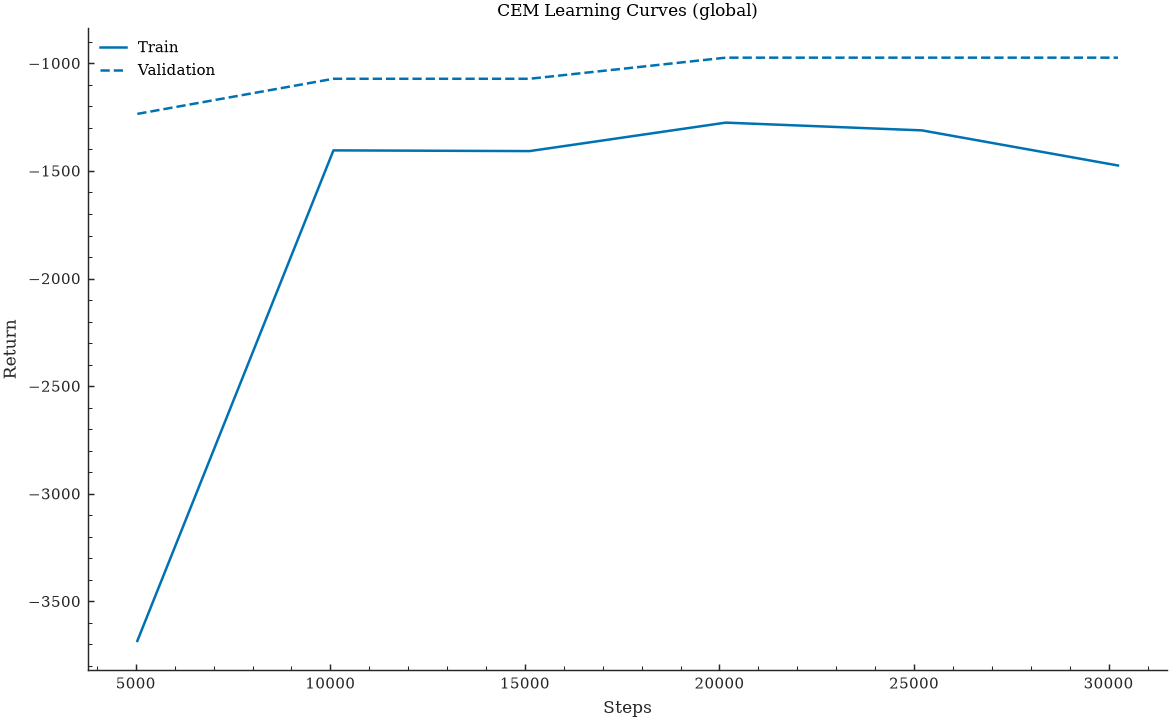

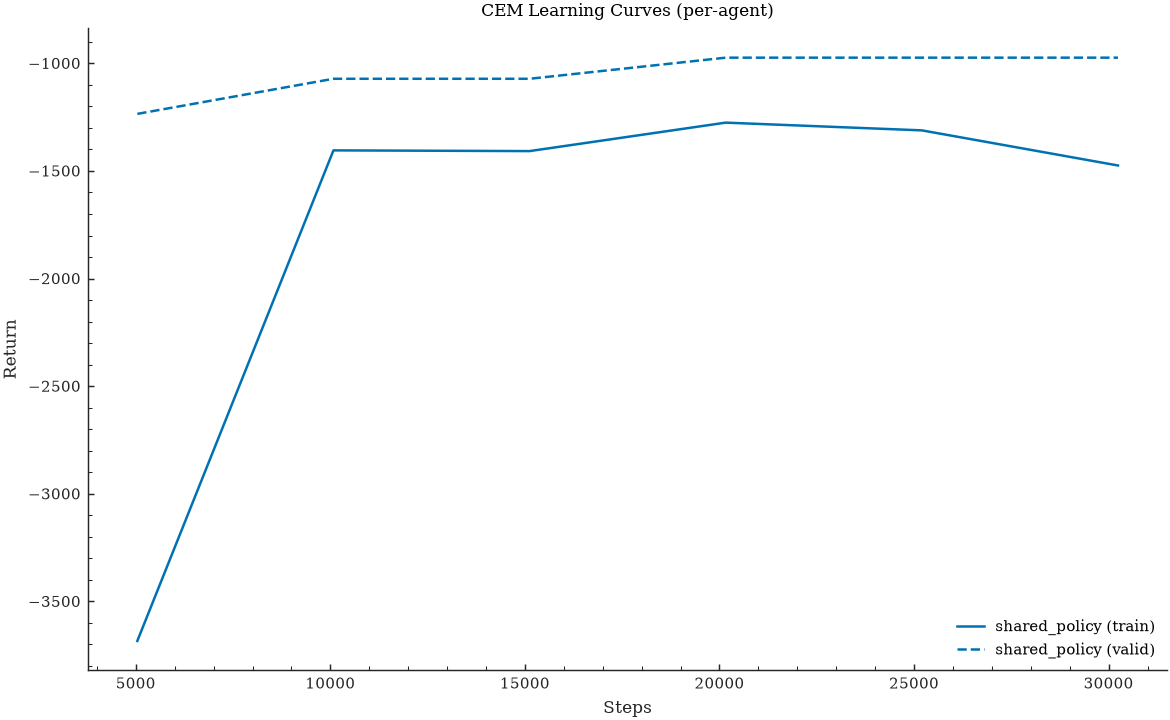

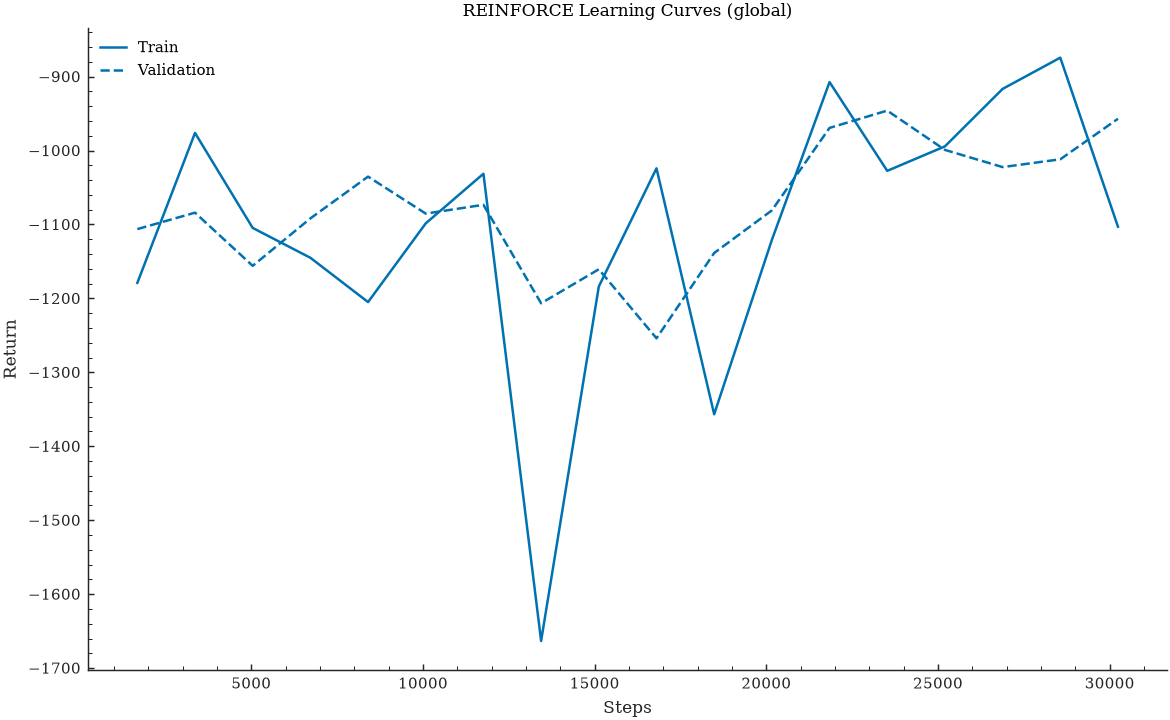

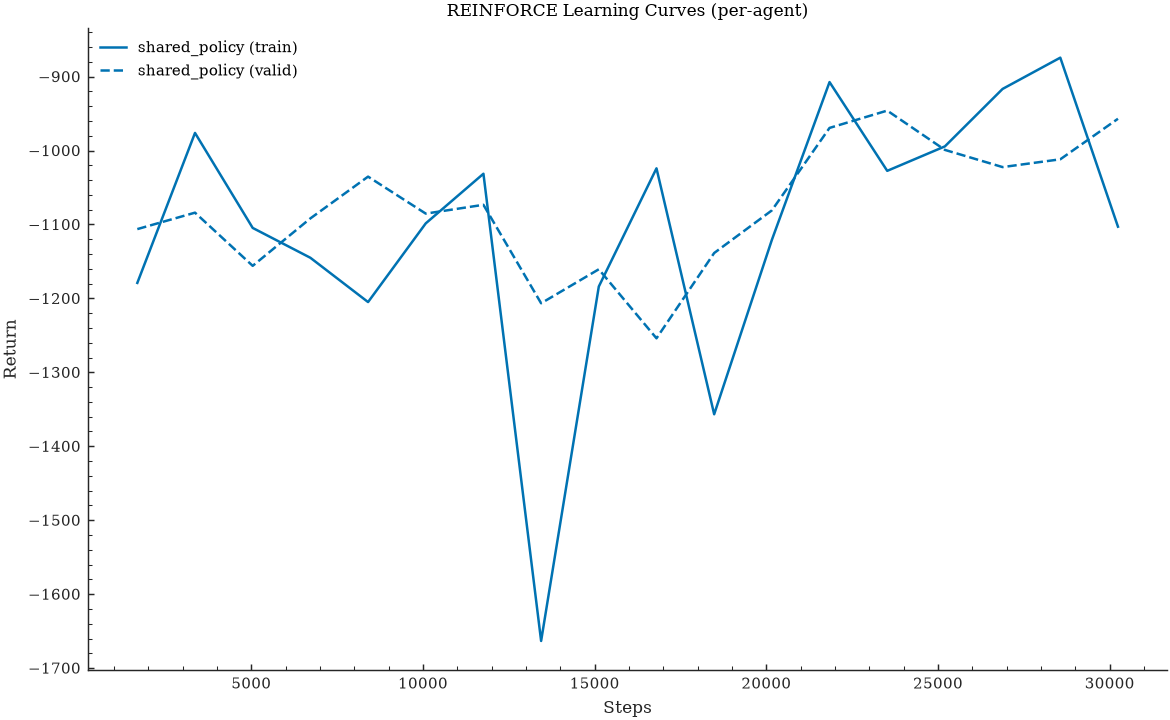

In [10]:
cem_curves = plot_learning_curves(paths_cem, title="CEM Learning Curves")
reinforce_curves = plot_learning_curves(
    paths_reinforce, title="REINFORCE Learning Curves"
)

#### **3.1.2 Policy evaluation**

In [11]:
results_cem = evaluate_marl_policy(env, best_policy_cem, num_episodes=NUM_EVAL_EPISODES)
results_reinforce = evaluate_marl_policy(
    env, best_policy_reinforce, num_episodes=NUM_EVAL_EPISODES
)

### **3.2 Your turn**

Write your algorithm in the cell below. Running that cell saves it as `algorithms/student_algorithm.py` (via the `%%writefile` command), which is then imported and trained in the following cells. Define the `train()` method with the logic of your optimization algorithm and extend the dataclass `AlgorithmConfig` with any extra hyperparameters you need.

📏 **Rules**
* The signature of `train` cannot be altered.
    * The input arguments and its order should be:
        * `env`: an instance of `MARLEnv`.
        * `agent_policy`: a single, not-yet-trained `PolicyNetwork` shared by all agents.
        * `config`: an instance of the dataclass `AlgorithmConfig` containing the hyperparameters to be used in the training run.
        * `seed`: integer number to ensure reproducibility, optional.
    * The function should return a tuple with two elements:
        * The trained shared `PolicyNetwork`.
        * A dict containing the path where the policy checkpoint is saved.
* The allowed Python packages are limited to those provided in [pyproject.toml](pyproject.toml).
* Include group member information in the module docstring.

<div class="alert alert-block alert-warning">
<b>🏷️ Note:</b> the first line of the cell must be <code>%%writefile algorithms/student_algorithm.py</code>: do not add code or comments above it. Every time the cell is run, the file is overwritten.
</div>


In [ ]:
%%writefile algorithms/student_algorithm.py
"""Group XX: <member names>. Implementation of my own RL algorithm."""

from dataclasses import dataclass

from course_package import MARLEnv
from course_package.policies.rl.networks import PolicyNetwork
from course_package.utils.helpers import (
    BaseAlgorithmConfig,
    set_seed,
)


@dataclass
class AlgorithmConfig(BaseAlgorithmConfig):
    """Hyperparameter specification for Custom Algorithm."""

    hyperparameter_1: float = 0.5
    hyperparameter_2: int = 10
    group_identifier: str = "GROUP_NAME"


def train(
    env: MARLEnv,
    agent_policy: PolicyNetwork,
    config: AlgorithmConfig,
    seed: int = 0,
) -> tuple[PolicyNetwork, dict[str, str]]:
    """
    Train the single policy shared by all agents.
    `env` returns observations of shape (num_agents, num_features), which
    `agent_policy` can process in one batched call.
    """
    set_seed(seed)

    # YOUR CODE GOES HERE

    return agent_policy, {}


Writing algorithms/student_algorithm.py


In [14]:
import importlib

from algorithms import student_algorithm

importlib.reload(student_algorithm)  # pick up the latest version of your file
from algorithms.student_algorithm import AlgorithmConfig, train


In [ ]:
policy = make_shared_policy(num_features, num_actions)
config = AlgorithmConfig(group_identifier="GroupXXX")
best_policy, paths = train(env, policy, config=config, seed=0)

learning_curves = plot_learning_curves(paths, title="Learning Curves")

In [16]:
results = evaluate_marl_policy(env, best_policy, num_episodes=NUM_EVAL_EPISODES)

### **3.3 Submit your algorithm**
When you are happy with your algorithm, copy it to the `outputs/submissions` folder using your group identifier (this also checks that `train` and `AlgorithmConfig` are defined).

In [17]:
export_submission(
    "algorithms/student_algorithm.py", group_id="G00"
)  # TODO: your group id

Submission saved to outputs/submissions/G00.py


PosixPath('outputs/submissions/G00.py')

## **4. Result comparison**

### **Expert reference**
<div class="alert alert-block alert-info">
<b>💡 Tip:</b> the <em>expert</em> is a model-based controller that is <b>not</b> learned: a model predictive controller (MPC) for the EV battery and a PID controller for the heat pump. It knows the system model and receives forecasts, so it is a strong reference to compare your learned policy against, not a rival you are expected to beat within the training budget. It needs no training and is <b>not</b> part of the grading.
</div>

In [ ]:
expert = make_expert(env)
results_expert = evaluate_expert(env, expert, num_episodes=NUM_EVAL_EPISODES)

CEM: test return -1353.6 +/- 418.3
REINFORCE: test return -1046.6 +/- 122.3
Your Algorithm: test return -1471.7 +/- 688.7


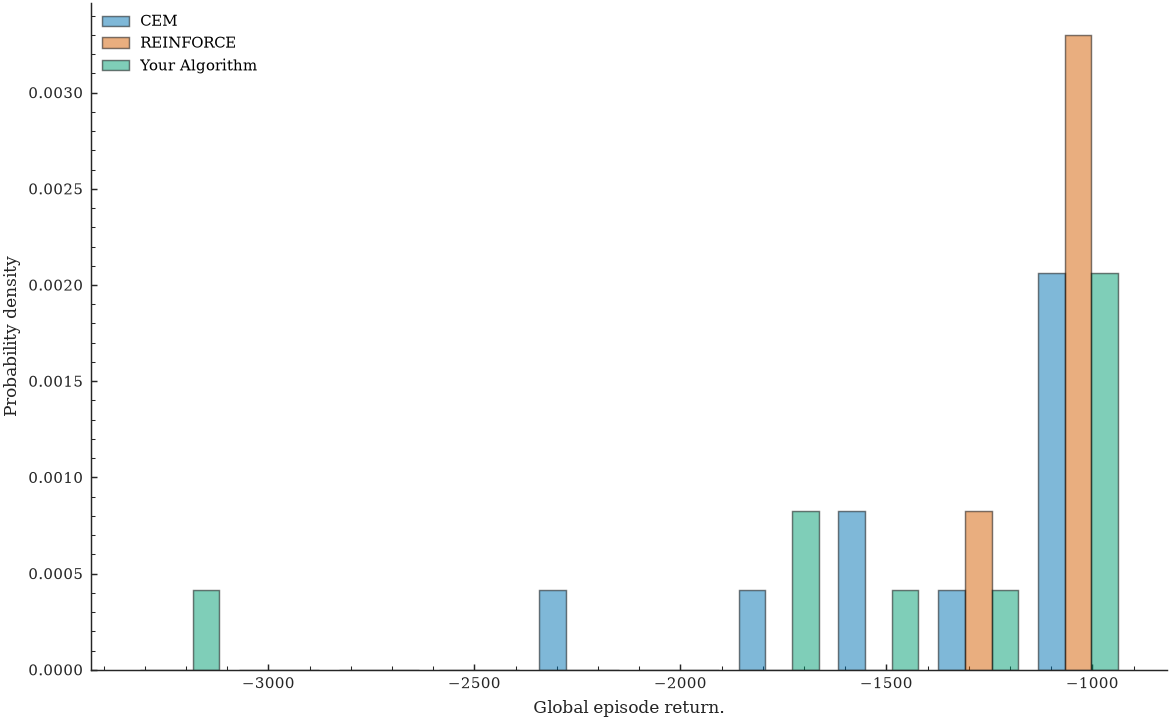

In [ ]:
global_returns_expert = np.sum(results_expert, axis=1)
global_returns_cem = np.sum(results_cem, axis=1)
global_returns_reinforce = np.sum(results_reinforce, axis=1)
global_returns = np.sum(results, axis=1)

reward_figure = plot_reward_distribution(
    [global_returns_expert, global_returns_cem, global_returns_reinforce, global_returns],
    labels=["Expert (MPC + PID)", "CEM", "REINFORCE", "Your Algorithm"],
)
for name, values in [
    ("Expert (MPC + PID)", global_returns_expert),
    ("CEM", global_returns_cem),
    ("REINFORCE", global_returns_reinforce),
    ("Your Algorithm", global_returns),
]:
    print(f"{name}: test return {values.mean():.1f} +/- {values.std():.1f}")